# Correlation Table of speed vs Vehicles data

In [26]:
import numpy as np
import pandas as pd
from pandas import DataFrame, concat
import os,itertools
from datetime import datetime
import calendar

In [27]:
ROUTE_LIST = ['b_PIE', 'b_Woodlands']
read_df = pd.read_csv('regression_input_all_transformer.csv')
wood_df  = read_df.loc[(read_df['Route']==ROUTE_LIST[1])]
pie_df  = read_df.loc[(read_df['Route']==ROUTE_LIST[0])]

In [28]:
def get_correlation(df, Route):
    pdf = pd.DataFrame(columns=df["X5_Day_name"].unique().tolist())
    
    month_list = df["X14_Month"].unique().tolist()
    
    for i in range(len(month_list)):
        
        #compute correlation of every month
        for day in df["X5_Day_name"].unique().tolist():
            
            #Compute the correlation matrix
            temp_df = df.loc[df['X14_Month'].eq(month_list[i]) & df['X5_Day_name'].eq(day)][['X1_Vehicles_no_filter','Y_Speed']].corr()
            
            ## Fill the day with corresponding correlation 
            pdf.at[i, day]=temp_df.at['X1_Vehicles_no_filter', 'Y_Speed']
        
        ## fill the month column
        pdf.loc[i, ['Month']] =  month_list[i]
        pdf.loc[i, ['Route']] = Route
    
    return pdf
wood_corr = get_correlation(wood_df, ROUTE_LIST[1])
pie_corr = get_correlation(pie_df, ROUTE_LIST[0])
final_df =  [wood_corr,pie_corr]
result = pd.concat(final_df)

# Assume 'Month' is the column containing the month number in your DataFrame
result['Month'] = result['Month'].astype(int)  # Convert column to integers
result['Month'] = result['Month'].apply(lambda x: calendar.month_name[x])

#Rearrange the column order
column_order = ['Route', 'Monday'] + [col for col in result.columns if col not in ['Route', 'Monday']]
result = result.reindex(columns=column_order)

result.to_csv("1.correlation_speed_Vs_total vehicles.csv",index=False)
result

,Route,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday,Month
0,b_Woodlands,-0.42387,-0.40455,-0.384194,-0.405922,-0.407969,-0.194141,-0.086099,March
1,b_Woodlands,-0.391668,-0.40452,-0.47548,-0.307189,-0.07401,-0.062467,0.067791,April
2,b_Woodlands,-0.353159,-0.455073,-0.301613,-0.405515,-0.398572,0.024494,0.085383,May
3,b_Woodlands,-0.289359,-0.349687,-0.33905,-0.376866,-0.390316,-0.060293,0.055677,June
0,b_PIE,-0.452448,-0.438264,-0.404916,-0.462512,-0.451177,-0.419821,-0.339401,March
1,b_PIE,-0.40934,-0.456836,-0.362295,-0.316095,-0.18617,-0.406862,-0.197969,April
2,b_PIE,-0.448374,-0.419484,-0.408673,-0.375684,-0.353235,-0.322644,-0.295653,May
3,b_PIE,-0.415557,-0.420136,-0.418736,-0.472679,-0.444551,-0.480662,-0.2834,June


# Compute error score for report

In [29]:
june_wl  =  pd.read_csv(os.path.join('b_Woodlands_best_models', "b_Woodlands_june_speed_result.csv"))
june_wl.head(2)

,Timestamp,Route,X14_Month,Camera_id,Y_Speed,svr_m1,svr_m2,svr_m3,svr_m4,xgb_m1,...,lstm_m2,lstm_m3,lstm_m4,xgb_m2,xgb_m3,xgb_m4,rf_m2,rf_m1,rf_m3,rf_m4
0,2022-06-20 05:00:00,b_Woodlands,6,2703,81,79,76,81,81,78,...,81,82,82,78,82,82,80,78,82,82
1,2022-06-20 05:05:00,b_Woodlands,6,2703,81,79,77,81,80,78,...,82,82,82,78,81,82,80,77,82,82


In [30]:
june_pie  = pd.read_csv(os.path.join('b_PIE_best_models', "b_PIE_june_speed_result.csv"))
june_pie.head(2)

,Timestamp,Route,X14_Month,Camera_id,Y_Speed,svr_m1,svr_m2,svr_m3,svr_m4,xgb_m1,...,xgb_m3,xgb_m4,lstm_m1,lstm_m2,lstm_m3,lstm_m4,rf_m2,rf_m1,rf_m3,rf_m4
0,2022-06-20 05:00:00,b_PIE,6,2705,83,80,73,83,83,82,...,85,85,82,83,85,86,84,82,84,85
1,2022-06-20 05:05:00,b_PIE,6,2705,89,80,73,80,80,83,...,85,85,82,83,85,86,84,83,84,85


In [31]:
june_2way = pd.read_csv(os.path.join('2way_best_models', "2way_june_speed_result.csv"))
june_2way.head(2)

,Timestamp,Route,X14_Month,Camera_id,Y_Speed,svr_m1,svr_m2,svr_m3,svr_m4,xgb_m1,...,xgb_m3,xgb_m4,lstm_m1,lstm_m2,lstm_m3,lstm_m4,rf_m2,rf_m1,rf_m3,rf_m4
0,2022-06-20 05:00:00,b_Woodlands,6,2703,81,84,84,83,83,82,...,84,84,84,85,84,86,84,82,84,84
1,2022-06-20 05:05:00,b_Woodlands,6,2703,81,85,85,81,81,83,...,84,84,84,85,85,86,84,83,83,83


In [32]:
model_list = ['lstm_m1', 'xgb_m1', 'svr_m1','rf_m1',
              'lstm_m2', 'xgb_m2', 'svr_m2','rf_m2',
              'lstm_m3', 'xgb_m3', 'svr_m3','rf_m3',
              'lstm_m4', 'xgb_m4', 'svr_m4','rf_m4']

unique_models = []
unique_Algs = []

for model in model_list:
    # Split the model name into algorithm name and model name using '_' as the separator
    unique_Algs.append(model.split("_", maxsplit=1)[0])
    unique_models.append(model.split("_", maxsplit=1)[1])

## To preserve order
unique_Algs = list(set(unique_Algs))  # Remove duplicate algorithm names while preserving order
unique_models = list(set(unique_models))  # Remove duplicate model names while preserving order

print("Unique Algorithms:")
print(unique_Algs)

print("\nUnique Models:")
print(unique_models)


Unique Algorithms:
['rf', 'lstm', 'svr', 'xgb']

Unique Models:
['m3', 'm1', 'm2', 'm4']


In [33]:
model_list = ['lstm_m1', 'xgb_m1', 'svr_m1','rf_m1',
              'lstm_m2', 'xgb_m2', 'svr_m2','rf_m2',
              'lstm_m3', 'xgb_m3', 'svr_m3','rf_m3',
              'lstm_m4', 'xgb_m4', 'svr_m4','rf_m4']

unique_Algs = sorted(set([model.split("_", maxsplit=1)[0] for model in model_list]), key=lambda x: ['lstm', 'xgb', 'svr', 'rf'].index(x))
unique_models = sorted(set([model.split("_", maxsplit=1)[1] for model in model_list]), key=lambda x: int(x[1:]))

print("Unique Algorithms:")
print(unique_Algs)

print("\nUnique Models:")
print(unique_models)


Unique Algorithms:
['lstm', 'xgb', 'svr', 'rf']

Unique Models:
['m1', 'm2', 'm3', 'm4']


In [34]:
#https://datascienceparichay.com/article/python-split-string-by-underscore/
import numpy as np
from sklearn.metrics import mean_squared_error,explained_variance_score,mean_absolute_error


# Function to calculate error for each algorithm and model
def calculate_error(df, route, error_function):
    pdf = pd.DataFrame(columns=unique_models)
    pdf['Algorithm'] = unique_Algs
    pdf['Route'] = route
    pdf['error'] = error_function
        
    for i in range(len(model_list)):
        name_split = model_list[i].split("_", maxsplit=1)
        Algorithm = name_split[0]   # Extract the algorithm name (e.g., XGB)
        Model = name_split[1]     # Extract the model name (e.g., Wo_CURR_Y_LAG)
        
        # Calculate the error
        if(error_function=='rmse'):
            res = np.sqrt(mean_squared_error(df.Y_Speed, df[model_list[i]]))
        else:
            res = error_function(df.Y_Speed, df[model_list[i]])
        
        # Fill the corresponding column
        pdf.loc[unique_Algs.index(Algorithm), [Model]] = res
    
    # Rearrange the columns
    #pdf2 = pdf[pdf.columns[[5, 4, 0, 1, 2, 3, 6]]]
    
    #Rearrange the column order
    column_order = ['Route', 'Algorithm'] + [col for col in pdf.columns if col not in ['Route', 'Algorithm']]
    pdf = pdf.reindex(columns=column_order)

    return pdf



In [35]:
def calculate_all_errors(df,route):
    mse = calculate_error(df,route, 'rmse')
    mae = calculate_error(df,route, mean_absolute_error)
    exp = calculate_error(df,route, explained_variance_score)
    
    return  mse, mae, exp

mse_pie,mae_pie, exp_e_pie = calculate_all_errors(june_pie,"b_PIE")
mse_wl, mae_wl, exp_e_wl = calculate_all_errors(june_wl,"b_Woodlands")
mse_2way, mae_2way, exp_e_2way = calculate_all_errors(june_2way,'2way')

In [36]:
def concat_df(frames):
    # Concatenate the frames vertically (along the rows)
    return pd.concat(frames, axis=0, sort=False, ignore_index=True)

# Concatenate the dataframes vertically for MSE
frames = [mse_pie, mse_wl, mse_2way]
mse_result = concat_df(frames)

# Concatenate the dataframes vertically for MAE
frames = [mae_pie, mae_wl, mae_2way]
mae_result = concat_df(frames)

# Concatenate the dataframes vertically for explained variance score
frames = [exp_e_pie, exp_e_wl, exp_e_2way]
exp_result = concat_df(frames)

# Drop unnecessary columns from MAE result dataframe
mae_result.drop(["Route", "Algorithm"], axis=1, inplace=True)

# Drop unnecessary columns from explained variance score result dataframe
exp_result.drop(["Route", "Algorithm"], axis=1, inplace=True)


In [37]:
combined_output = pd.concat([mse_result, mae_result, exp_result], axis=1)

combined_output.to_csv("3.error_summary_transformer.csv",index=False)
combined_output

,Route,Algorithm,m1,m2,m3,m4,error,m1,m2,m3,m4,error,m1,m2,m3,m4,error
0,b_PIE,lstm,6.018054,5.856139,7.615186,7.485608,rmse,3.353651,3.252964,3.756813,3.658207,<function mean_absolute_error at 0x000001CF4D2...,0.69862,0.713868,0.512163,0.525226,<function explained_variance_score at 0x000001...
1,b_PIE,xgb,5.856903,5.68874,6.940758,6.842214,rmse,3.439983,3.412731,3.916164,3.847306,<function mean_absolute_error at 0x000001CF4D2...,0.710226,0.726703,0.592229,0.603706,<function explained_variance_score at 0x000001...
2,b_PIE,svr,7.316424,7.606631,8.656001,8.482425,rmse,4.496984,5.875806,6.443312,6.196172,<function mean_absolute_error at 0x000001CF4D2...,0.547688,0.518431,0.367826,0.395651,<function explained_variance_score at 0x000001...
3,b_PIE,rf,5.935283,5.76172,11.275093,10.008287,rmse,3.517579,3.390056,5.80882,4.887248,<function mean_absolute_error at 0x000001CF4D2...,0.702626,0.719802,0.034185,0.193578,<function explained_variance_score at 0x000001...
4,b_Woodlands,lstm,3.989827,3.783081,4.39866,4.132969,rmse,2.542122,2.459282,2.622777,2.902964,<function mean_absolute_error at 0x000001CF4D2...,0.70977,0.739079,0.622931,0.723733,<function explained_variance_score at 0x000001...
5,b_Woodlands,xgb,3.989221,3.758838,6.38331,5.342308,rmse,2.624649,2.537285,4.227457,3.594852,<function mean_absolute_error at 0x000001CF4D2...,0.702403,0.736882,0.223599,0.450545,<function explained_variance_score at 0x000001...
6,b_Woodlands,svr,4.888364,4.902147,7.278106,7.2227,rmse,3.499532,3.450702,5.604212,5.578939,<function mean_absolute_error at 0x000001CF4D2...,0.552811,0.563729,0.130709,0.217485,<function explained_variance_score at 0x000001...
7,b_Woodlands,rf,4.201719,3.996313,8.470625,7.28509,rmse,2.831669,2.705616,5.997972,4.83947,<function mean_absolute_error at 0x000001CF4D2...,0.66873,0.70304,0.000197,-0.014755,<function explained_variance_score at 0x000001...
8,2way,lstm,8.350498,8.388576,9.51598,8.376566,rmse,4.869596,4.898387,5.103663,4.872092,<function mean_absolute_error at 0x000001CF4D2...,0.132944,0.126037,-0.125427,0.146745,<function explained_variance_score at 0x000001...
9,2way,xgb,8.011106,8.014594,8.451558,7.830731,rmse,4.873072,4.833051,5.253053,5.026562,<function mean_absolute_error at 0x000001CF4D2...,0.202951,0.202486,0.112124,0.237525,<function explained_variance_score at 0x000001...


In [38]:
def generate_hour_vs_speed(df, model_to_plot, route, month):
    # Print a new line for separation
    print()
    
    # Set the figure size
    plt.figure(figsize=(10, 6))
    
    # Set the title of the plot
    title = "Speed of vehicles each hour at " + route + " in the month of " + month
    plt.title(title, fontsize=17)
    
    # Set the figure size using sns.set
    sns.set(rc={'figure.figsize':(11.7, 8.27)})
    
    # Set the color palette for the plot
    palette = sns.color_palette("mako_r", 7)
    
    # Create the line plot
    ax = sns.lineplot(data=df, x=df.hour, y=model_to_plot, hue="X5_Day_name", style="X5_Day_name",
                      markers=True, dashes=False, legend="full", linewidth=6)
    
    # Set the X-axis limits and format
    ax.set(xlim=(5, 23))
    
    # Set the font size for legend texts and title
    plt.setp(ax.get_legend().get_texts(), fontsize='13')  # for legend text
    plt.setp(ax.get_legend().get_title(), fontsize='13')  # for legend title
    
    # Set the x-label and y-label
    plt.xlabel("Hour", fontsize=15)
    plt.ylabel("Speed", fontsize=15)
    
    # Set the font size for x-axis and y-axis tick labels
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    
    # Show the plot
    plt.show()

    

# plot speed for unseen data

In [39]:
import seaborn as sns
from matplotlib import pyplot as plt, dates as mdates
import warnings

UNSEEN_DATA_FOLDER = "test_data_unseen"

def generate_time_vs_speed(df, model_to_plot, route, month):
    # Create a figure and axis with a specified figsize
    fig, ax = plt.subplots(figsize=(40, 20))
    
    # Create a line plot using sns.lineplot
    ax = sns.lineplot(data=df, x='hh_mm', y=model_to_plot, hue='X5_Day_name', style="X5_Day_name",
                      markers=True, dashes=False, linewidth=7, errorbar=None)
    
    # Set the x-label and y-label
    plt.xlabel(" Hour ", fontsize=50)
    plt.ylabel(" Speed Km/hr ", fontsize=50)
    
    # Adjust the label position to include a space
    plt.gca().xaxis.set_label_coords(0.5, -0.08)  # Adjust the second parameter for vertical spacing
    plt.gca().yaxis.set_label_coords(-0.04, 0.5)  # Adjust the first parameter for horizontal spacing

    # Set the font size for x-axis and y-axis tick labels
    plt.xticks(fontsize=50)
    plt.yticks(fontsize=50)
    
    plt.ylim(40, 90)
    
    # Get the legend handles and set the linewidth for the legend lines
    handles, labels = ax.get_legend_handles_labels()
    for handle in handles:
        handle.set_linewidth(5)  # Set the desired linewidth for the legend lines
    
    # Recreate the legend with the modified handles
    ax.legend(handles, labels, fontsize=40)
    
    # Set the title
    title = f"Speed of vehicles every hour at {route} in the month of {month}"
    #plt.title(title, fontsize=50, pad=20)
    print()
    
    fileName = os.path.join(UNSEEN_DATA_FOLDER, route + "_" + month + "_plot.png")
    print(fileName)
    plt.savefig(fileName, format="png", bbox_inches="tight", dpi=600)
    
    # Show the plot
    plt.show()



def read_and_plot(fileName, model_name, route, month):
    # Read the CSV file into a DataFrame
    read_df = pd.read_csv(os.path.join(UNSEEN_DATA_FOLDER, fileName))
    
    # Filter the DataFrame based on the provided route
    df = read_df.loc[(read_df['Route'] == route)].copy() 
    
    # Convert the 'Timestamp' column to datetime format
    df['Timestamp'] = pd.to_datetime(df['Timestamp'])
    
    # Extract the hour and minute from the 'Timestamp' column
    df['hh_mm'] = df['Timestamp'].dt.strftime('%H')
    
    df = df.loc[(df['hh_mm'] != '04')]
    
    # Call the 'generate_time_vs_speed' function to generate the plot
    generate_time_vs_speed(df, model_name, route, month)

    

## Plot for July


test_data_unseen\b_PIE_july_plot.png


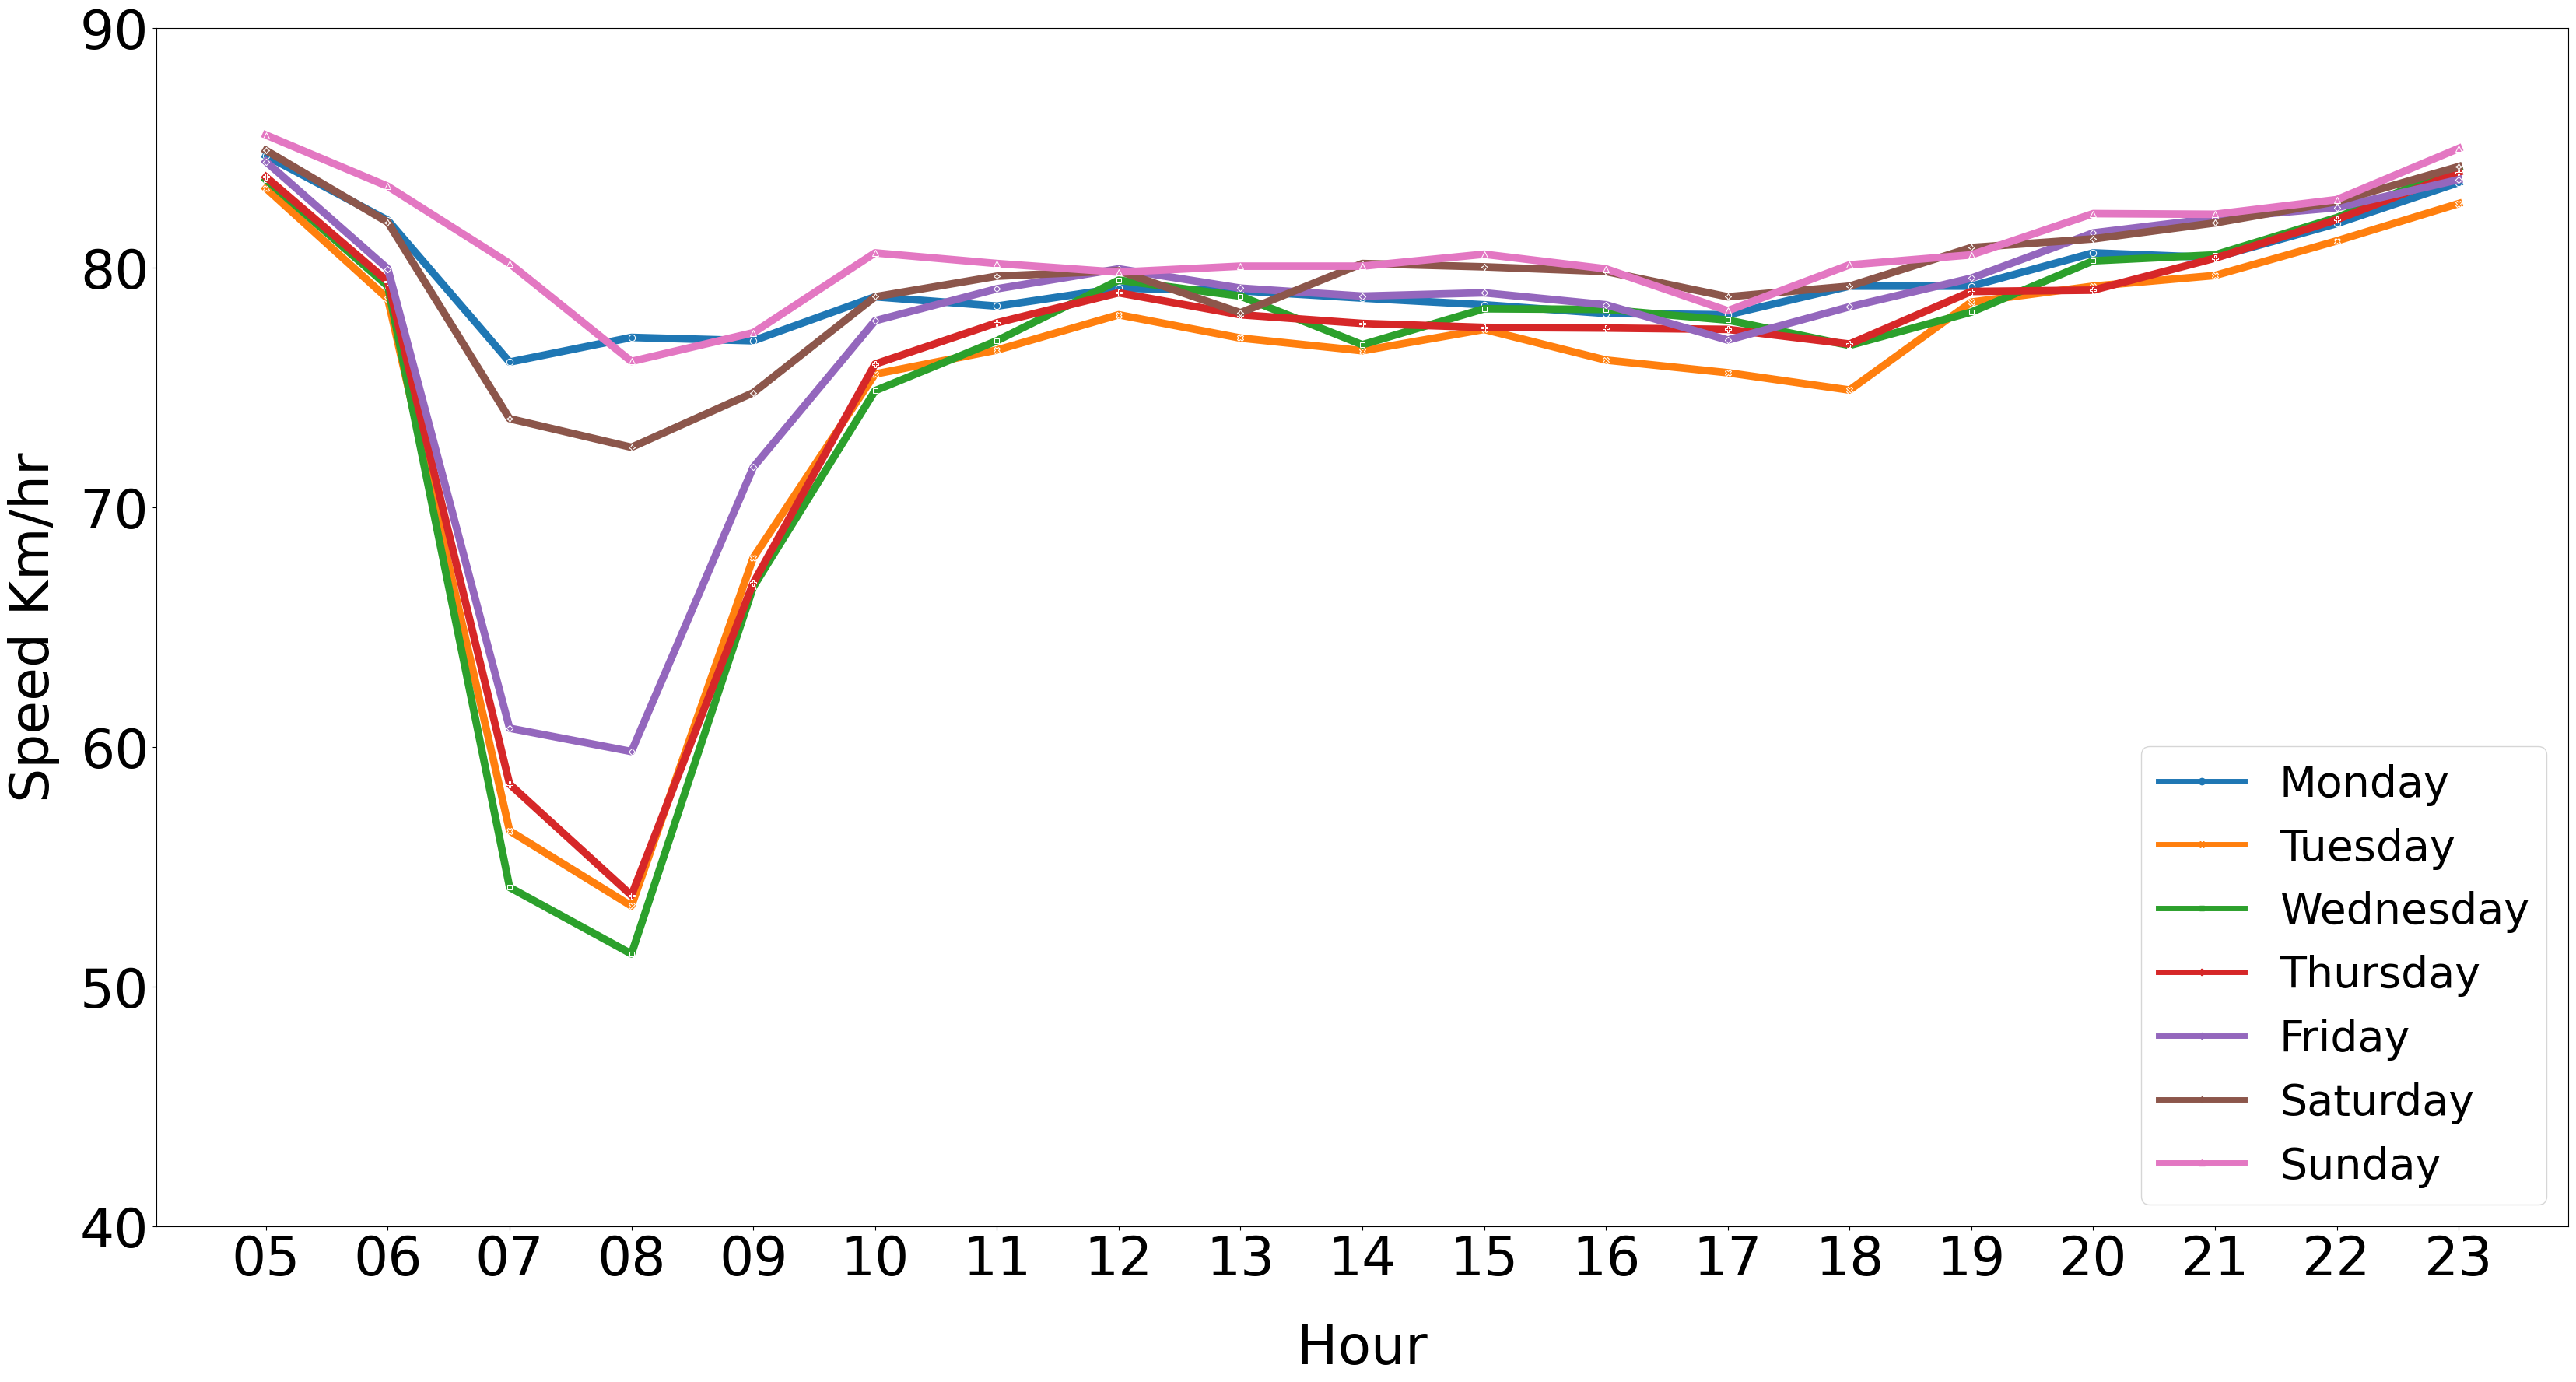

In [40]:
fileName = "jul_full_b_PIE.csv"
model_name = "xgb_m2"
read_and_plot(fileName, model_name, "b_PIE", "july" )


test_data_unseen\b_Woodlands_july_plot.png


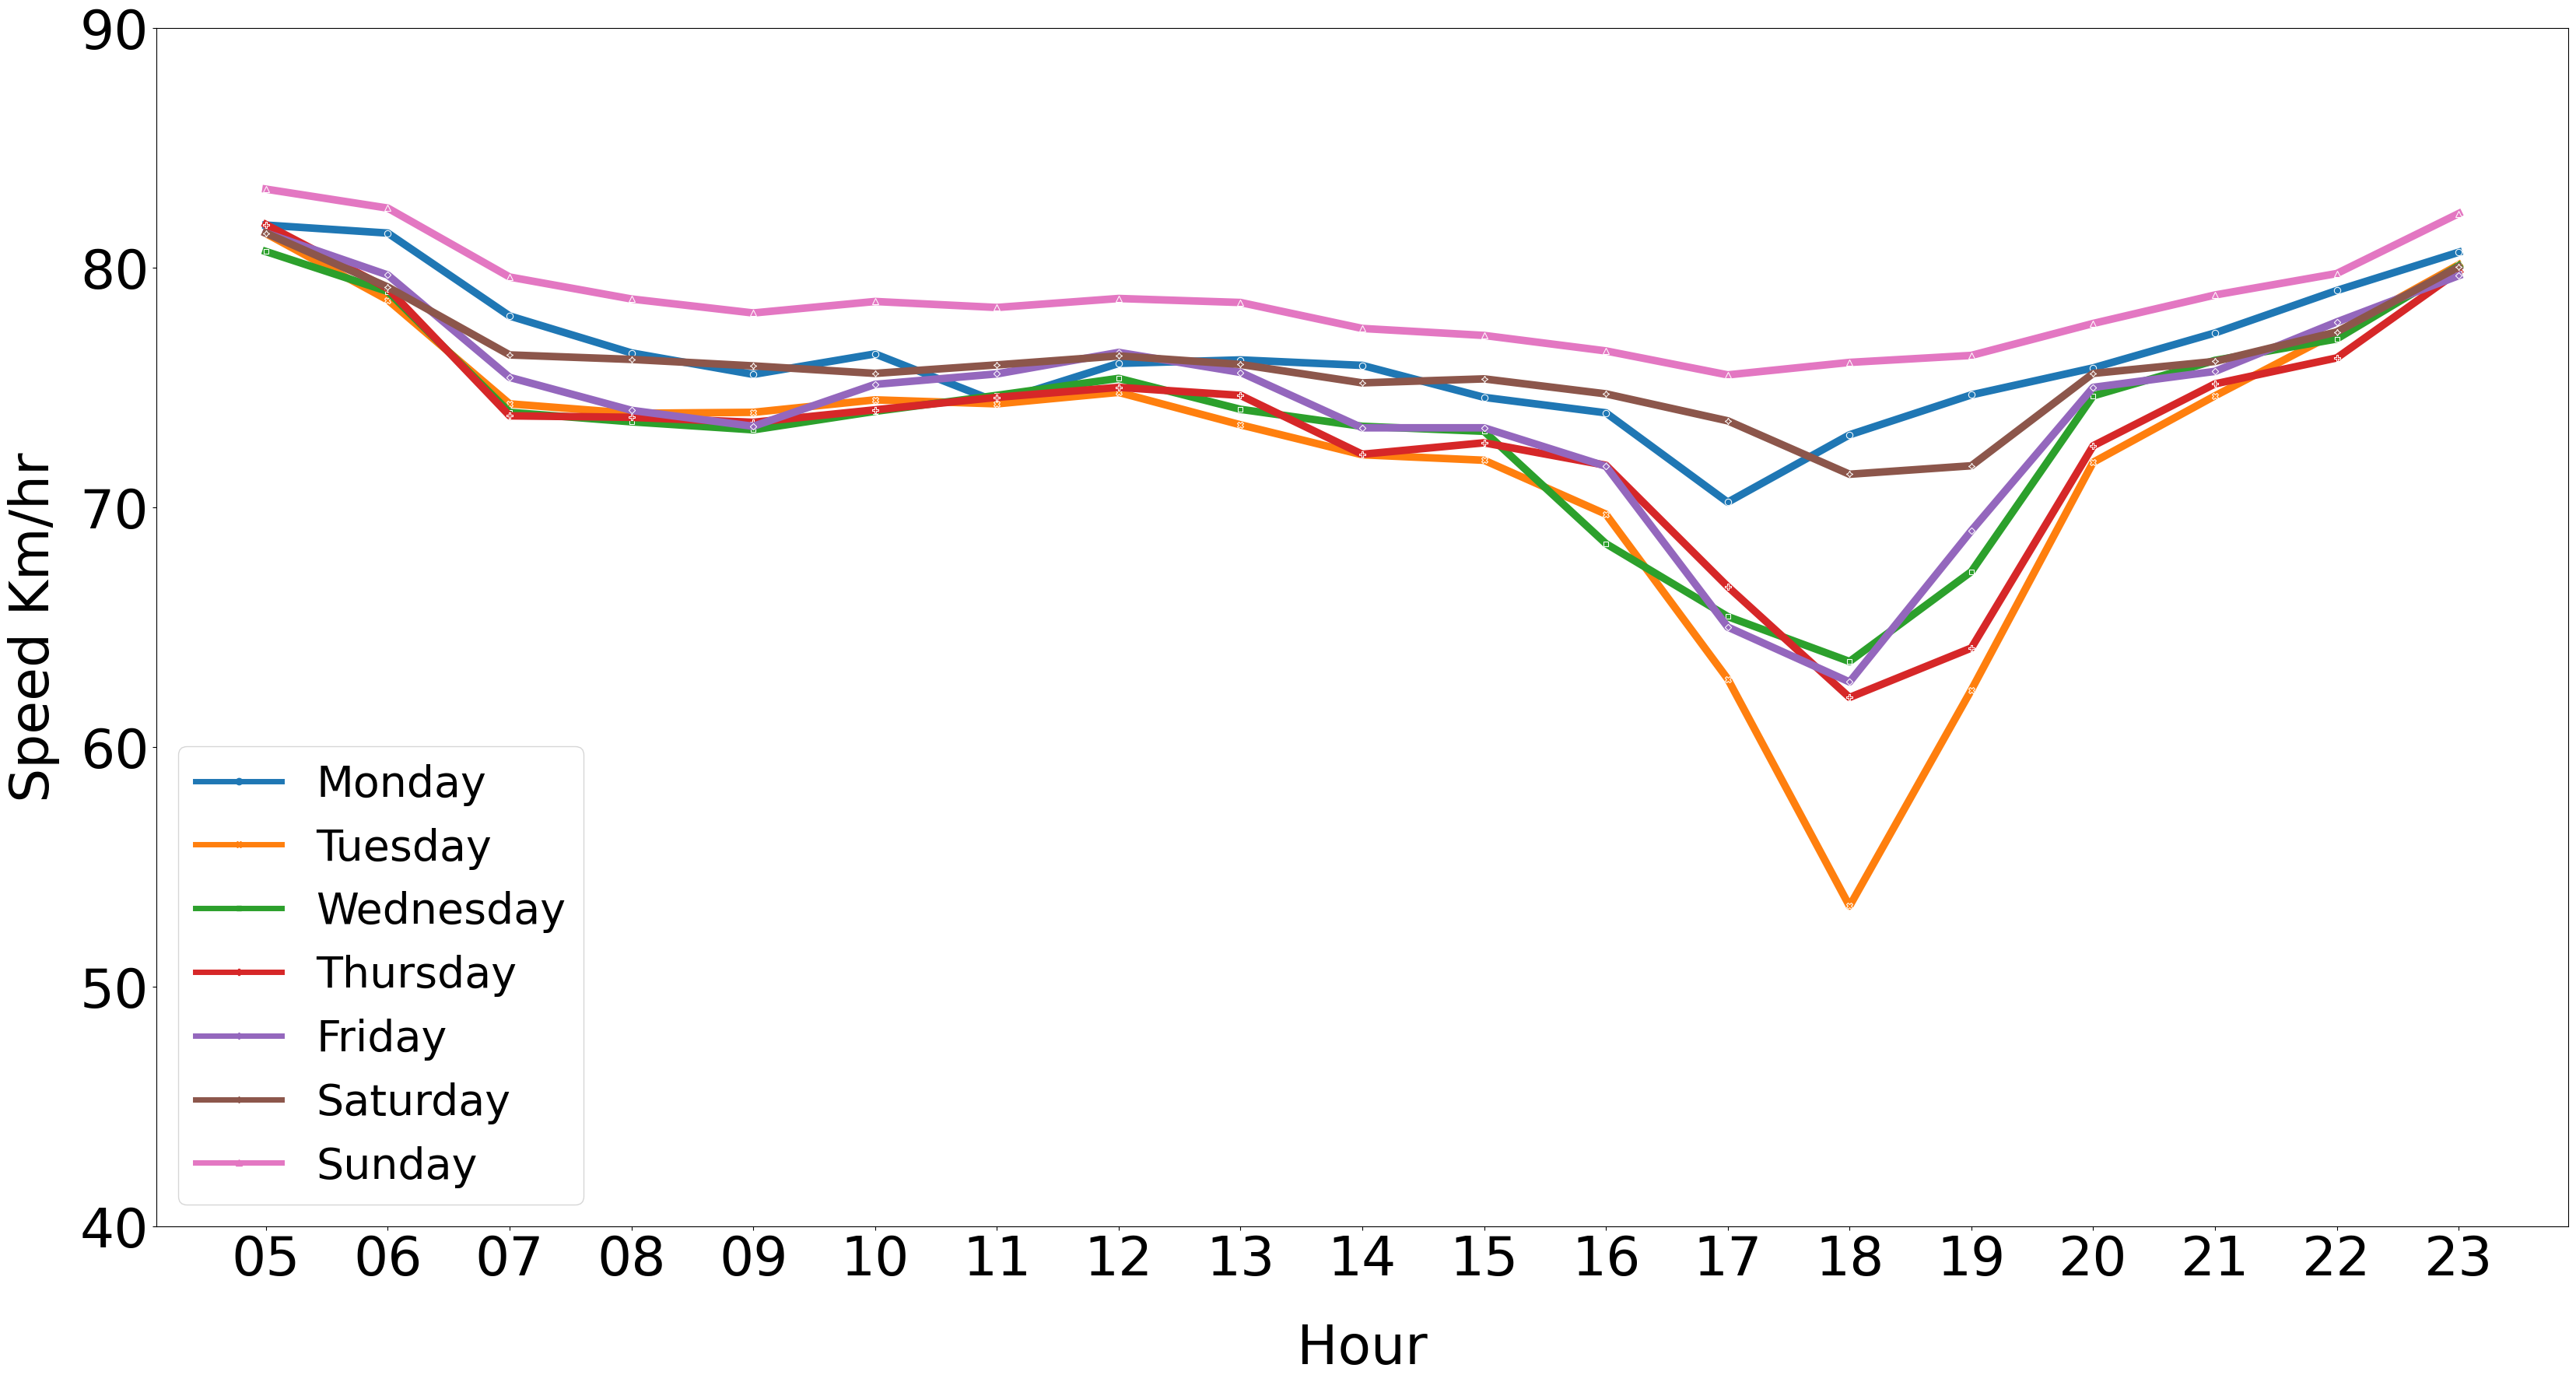

In [41]:
fileName = "jul_full_b_Woodlands.csv"
model_name = "xgb_m2"
read_and_plot(fileName,model_name, "b_Woodlands", "july"  )

## Plot for February


test_data_unseen\b_PIE_feb_plot.png


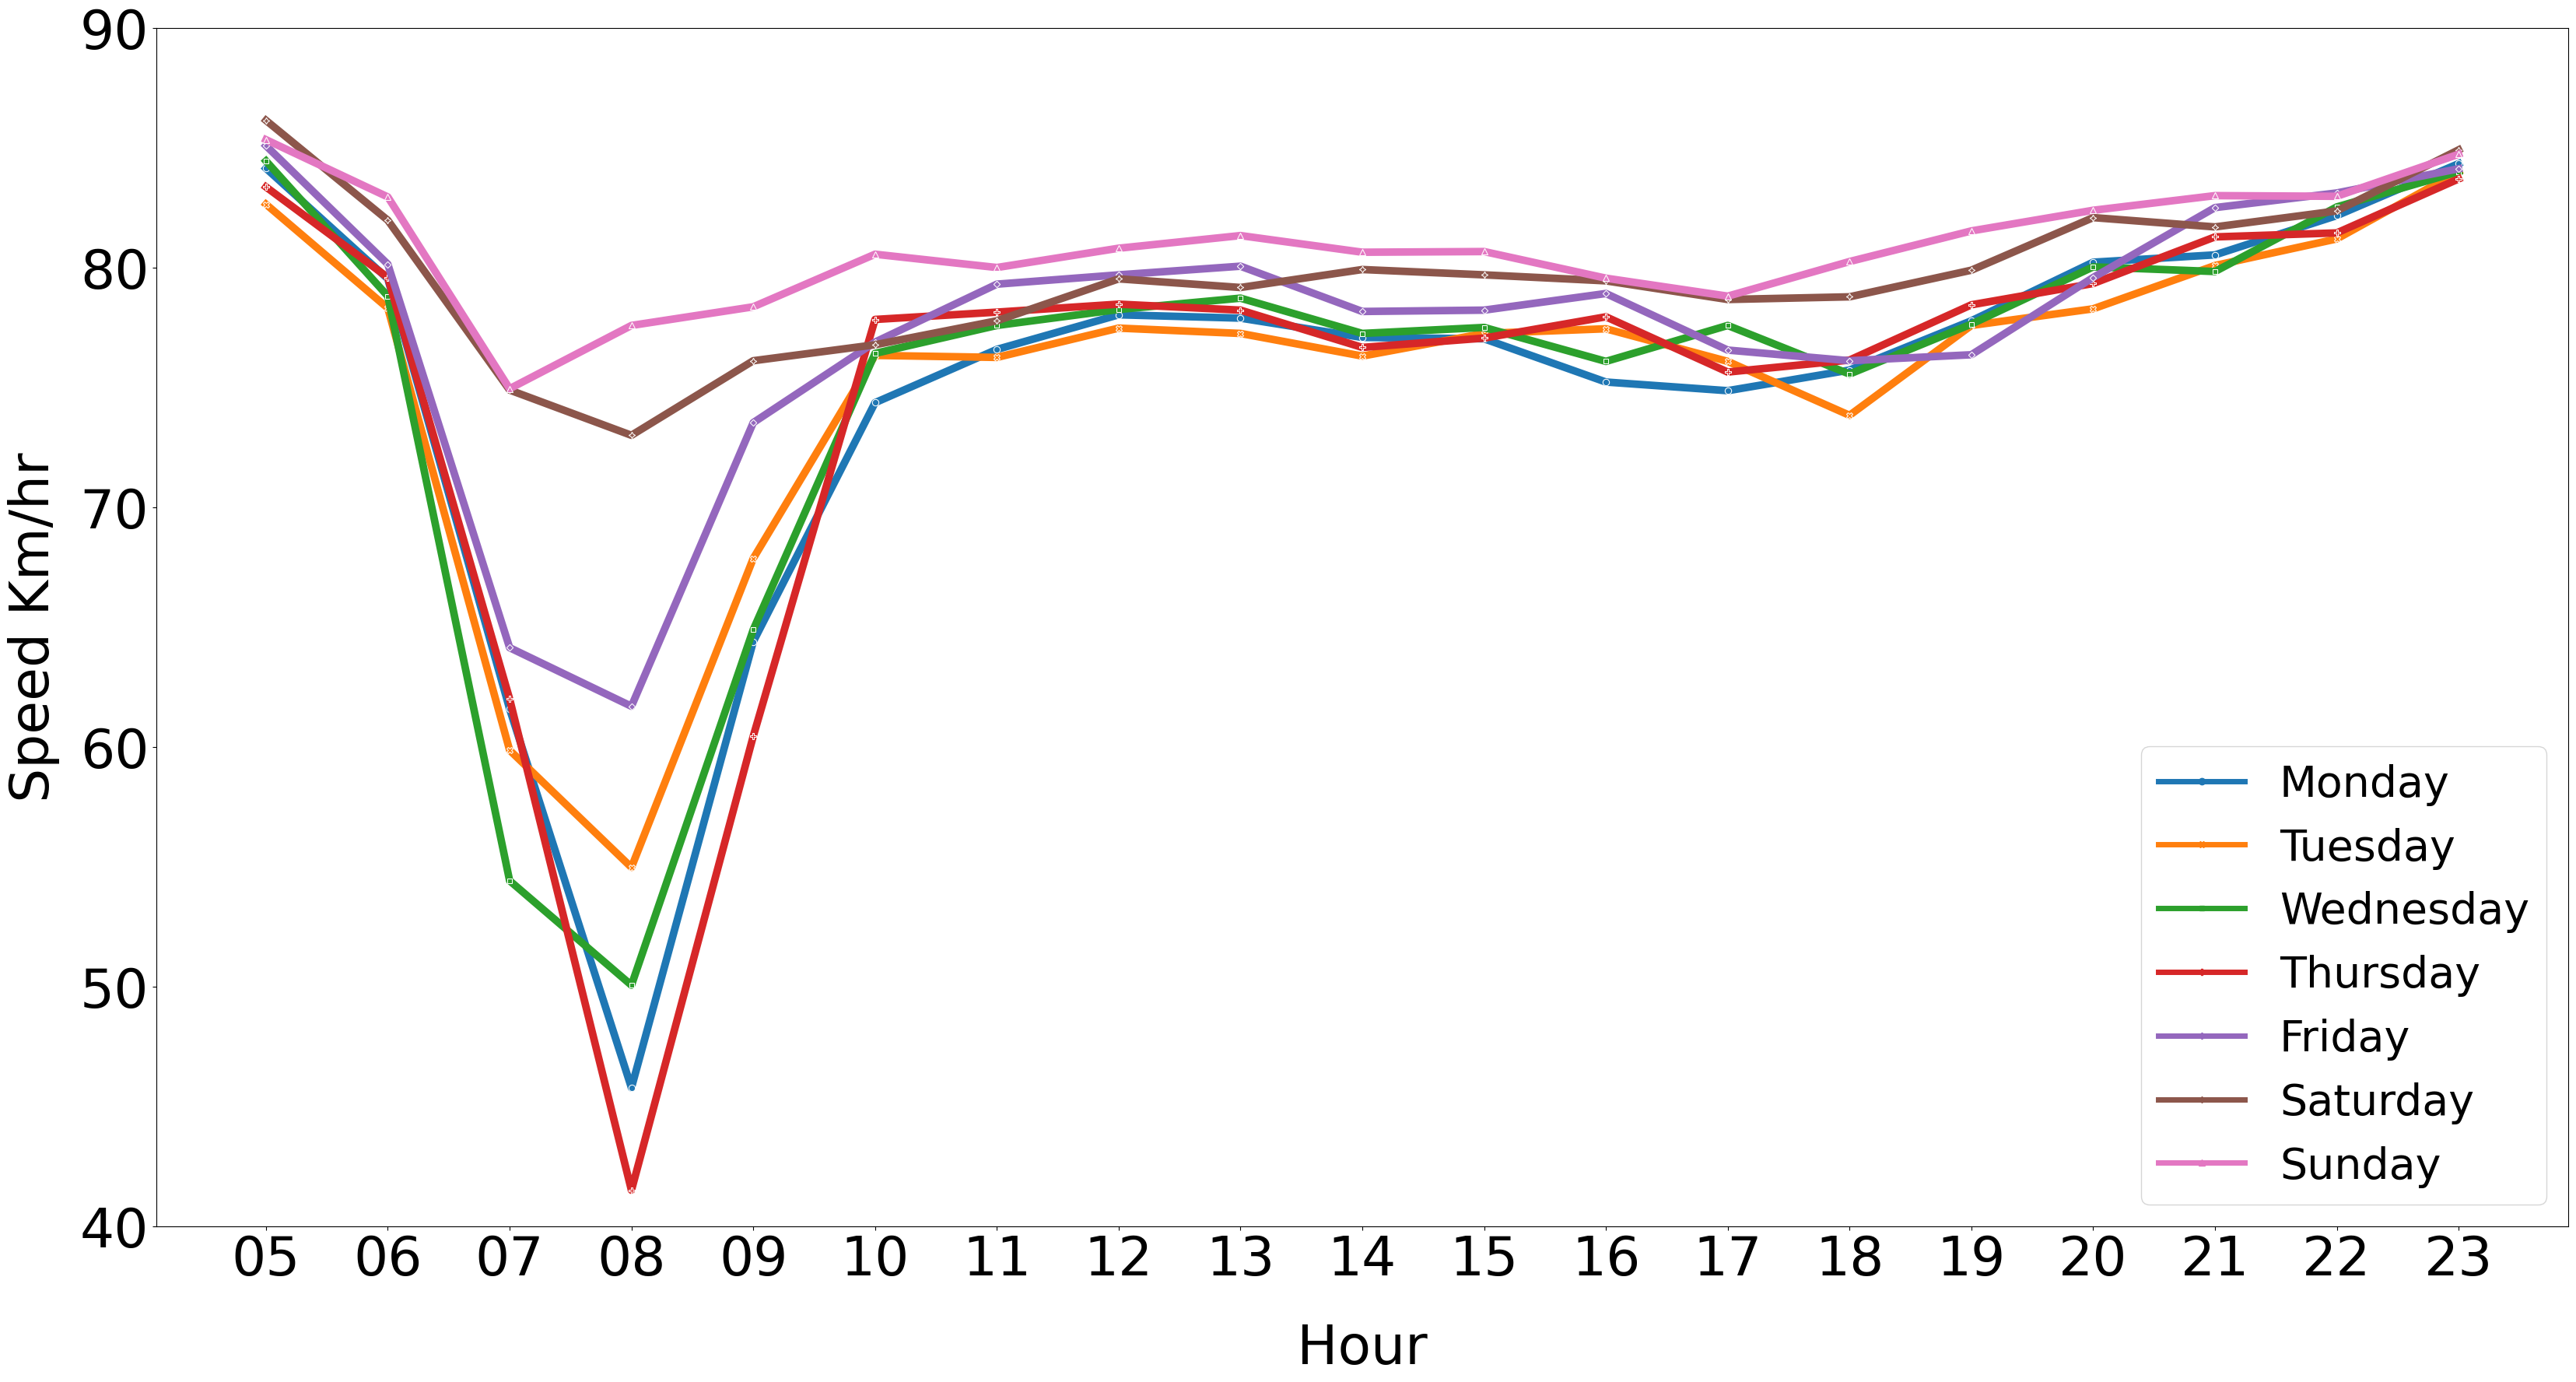

In [42]:
fileName = "feb_full_b_PIE.csv"
model_name = "xgb_m2"
read_and_plot(fileName,model_name,"b_PIE", "feb" )


test_data_unseen\b_Woodlands_feb_plot.png


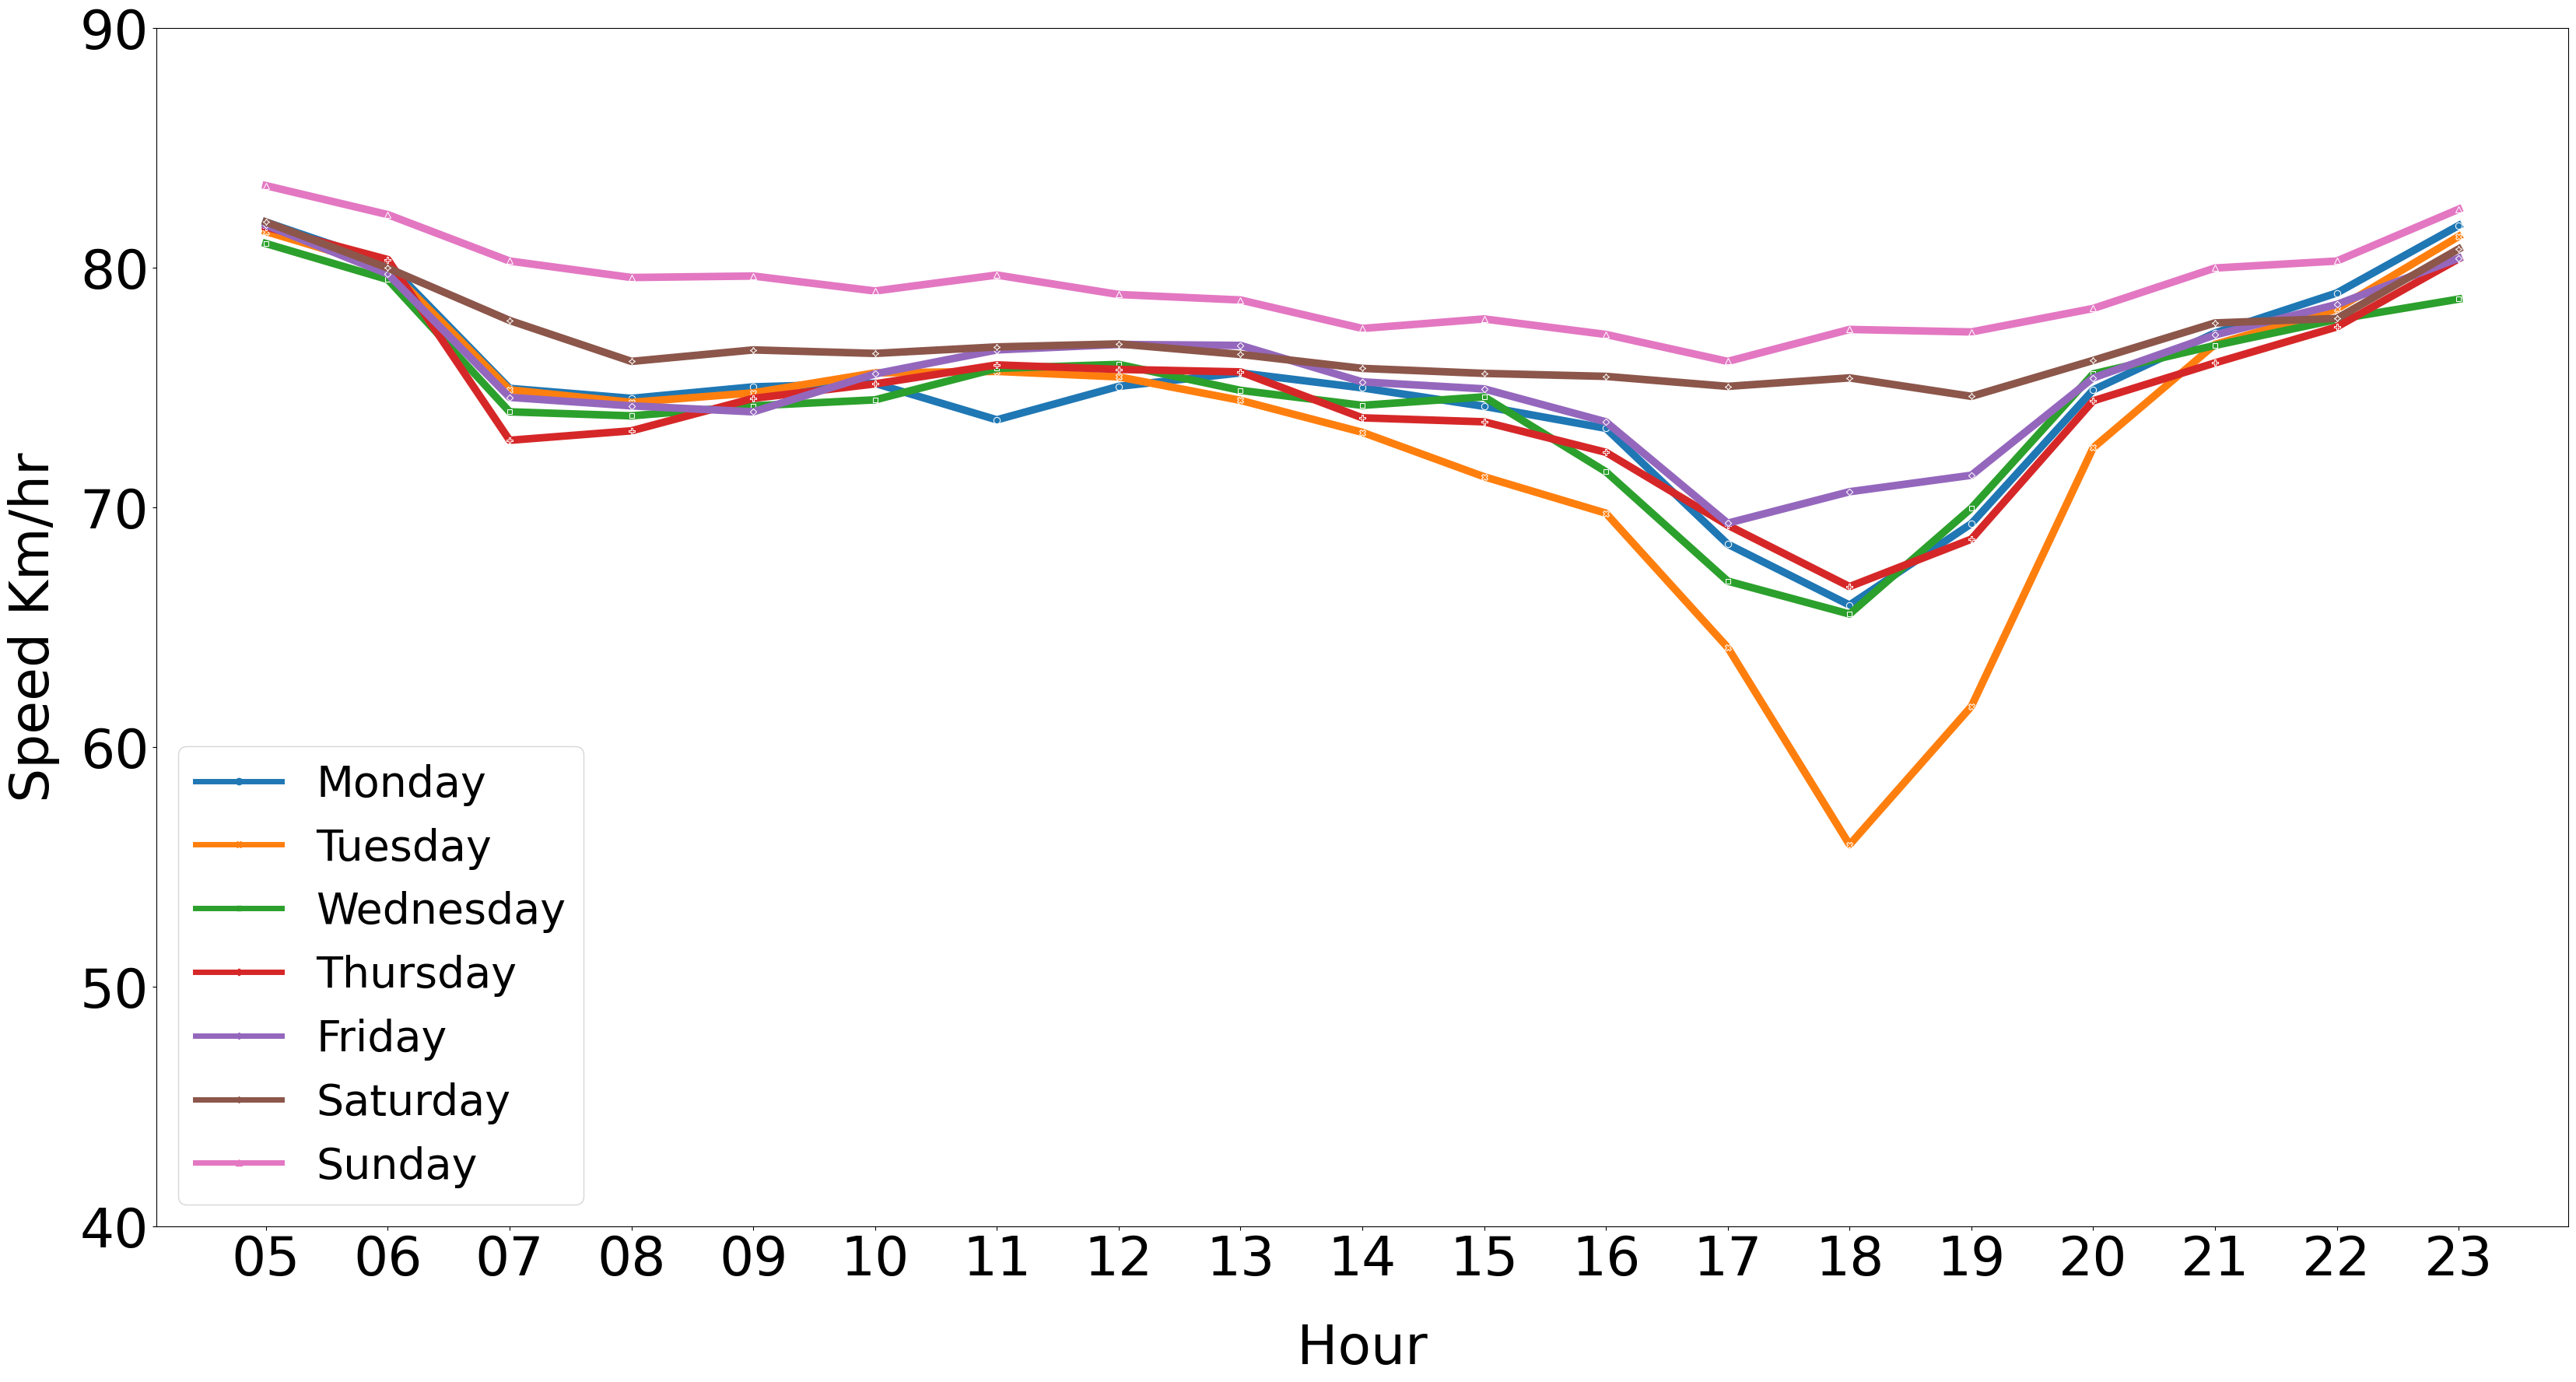

In [43]:
fileName = "feb_full_b_Woodlands.csv"
model_name = "xgb_m2"
read_and_plot(fileName,model_name, "b_Woodlands","feb" )

# Calculation model performance ratio

In [44]:
june_wl  =  pd.read_csv(os.path.join('b_Woodlands_best_models', "b_Woodlands_june_speed_result.csv"))
june_wl.columns

Index(['Timestamp', 'Route', 'X14_Month', 'Camera_id', 'Y_Speed', 'svr_m1',
       'svr_m2', 'svr_m3', 'svr_m4', 'xgb_m1', 'lstm_m1', 'lstm_m2', 'lstm_m3',
       'lstm_m4', 'xgb_m2', 'xgb_m3', 'xgb_m4', 'rf_m2', 'rf_m1', 'rf_m3',
       'rf_m4'],
      dtype='object')

### calculate the difference between the actual speed (Y_Speed) and the predicted speed for each model 

In [45]:
def find_predicted_speed_diff(input_df):
    df = input_df.copy()
    diff_model_names = []  # Initialize an empty list to store the new column names that contains speed diff
    
    for model_name in model_list:
        new_name = "diff_" + model_name  # Create the column name with prefix 'diff_'
        diff_model_names.append(new_name)  # Add the new column name to the list
        
        df[new_name] = df['Y_Speed'] - df[model_name]  # Calculate the difference and assign it to the new column
    
    return df, diff_model_names  # Return the updated DataFrame and the list of new column names

### Find the closest predicted model

In [46]:
from collections import Counter
def find_closest_predicted_model(df_w_speed_diff, diff_model_names):
    
    diff_cols = df_w_speed_diff[diff_model_names]
    
    # Find the absolute differences between values and zero for each row
    abs_diff = np.abs(diff_cols - 0)

    # Find the minimum absolute difference for each row
    min_abs_diff = abs_diff.min(axis=1)

    # Find the column names with the closest absolute difference to zero for each row
    closest_predicted_model = abs_diff.apply(lambda row: list(row[row == min_abs_diff[row.name]].index), axis=1).tolist()
    
    # Extract column names without the 'diff_' prefix
    closest_predicted_model = [[col.replace('diff_', '') for col in cols] for cols in closest_predicted_model]
    
    # Flatten the list of closest columns
    flat_closest_columns = [col for sublist in closest_predicted_model for col in sublist]

    # Count the occurrences of each model
    model_occurance_count = dict(Counter(flat_closest_columns))

    return closest_predicted_model , model_occurance_count


# Call the function to extract speed diff for each model
df_w_speed_diff, diff_model_names = find_predicted_speed_diff(june_wl)

closest_predicted_model, model_occurance_count = find_closest_predicted_model(df_w_speed_diff, diff_model_names)
june_wl['closest_predicted_model'] = closest_predicted_model

In [47]:
june_wl.head(2)

,Timestamp,Route,X14_Month,Camera_id,Y_Speed,svr_m1,svr_m2,svr_m3,svr_m4,xgb_m1,...,lstm_m3,lstm_m4,xgb_m2,xgb_m3,xgb_m4,rf_m2,rf_m1,rf_m3,rf_m4,closest_predicted_model
0,2022-06-20 05:00:00,b_Woodlands,6,2703,81,79,76,81,81,78,...,82,82,78,82,82,80,78,82,82,"[lstm_m2, svr_m3, svr_m4]"
1,2022-06-20 05:05:00,b_Woodlands,6,2703,81,79,77,81,80,78,...,82,82,78,81,82,80,77,82,82,"[xgb_m3, svr_m3]"


In [48]:
sorted_model_occurance_count = dict(sorted(model_occurance_count.items(), key=lambda item: item[1], reverse=True))
sorted_model_occurance_count

{'lstm_m3': 1570,
 'lstm_m1': 1459,
 'lstm_m2': 1382,
 'xgb_m2': 1300,
 'rf_m2': 1254,
 'rf_m1': 1250,
 'xgb_m1': 1239,
 'lstm_m4': 1198,
 'xgb_m4': 1045,
 'svr_m1': 1031,
 'svr_m2': 1020,
 'xgb_m3': 857,
 'rf_m4': 721,
 'rf_m3': 704,
 'svr_m3': 691,
 'svr_m4': 665}

In [49]:
total_rows = june_wl.shape[0]
total_rows

6410

In [50]:
model_occurance_ratio = {k: v / total_rows for k, v in sorted(model_occurance_count.items(), key=lambda item: item[1], reverse=True)}
model_occurance_ratio

{'lstm_m3': 0.24492979719188768,
 'lstm_m1': 0.22761310452418096,
 'lstm_m2': 0.215600624024961,
 'xgb_m2': 0.20280811232449297,
 'rf_m2': 0.19563182527301093,
 'rf_m1': 0.19500780031201248,
 'xgb_m1': 0.19329173166926678,
 'lstm_m4': 0.18689547581903276,
 'xgb_m4': 0.16302652106084242,
 'svr_m1': 0.16084243369734788,
 'svr_m2': 0.15912636505460218,
 'xgb_m3': 0.13369734789391577,
 'rf_m4': 0.1124804992199688,
 'rf_m3': 0.10982839313572543,
 'svr_m3': 0.1078003120124805,
 'svr_m4': 0.10374414976599064}